# Milestone 4 — Fiabiliser la solution et analyser les gains

**Objectif (slide 8 du cours).** Le Milestone 4 a deux parties :

1. **Suites de tests et résultats des tests** :
   - tests unitaires des fonctions du moteur ;
   - respect des contraintes ;
   - cas limites et hypothèses sur les données manquantes ;
   - tous les matériaux livrés, et les besoins des usines servis à temps.
2. **Analyse comparative avant / après** :
   - nouvelles distributions du remplissage et des coûts ;
   - économies réalisées face au potentiel.

**Principe.** Ce notebook ne relance pas l'optimisation : il lit les **sorties du Milestone 3** comme des fichiers et teste le livrable
réel. Seuls les tests unitaires et le test de reproductibilité appellent le moteur.

> Squelette : les cellules marquées `TODO` sont à compléter.

## 0. Entrées

| Entrée | Fichier | Rôle |
|---|---|---|
| Moteur | `src/delivery_schedule_optimization/planner.py` | tests unitaires des fonctions |
| Dataset consolidé (M1) | `data/consolidated_dataset_<imputation>.csv` | exhaustivité, quantités |
| Fichiers bruts | `docs/released_schedule.csv`, `docs/distances.csv` | hypothèses sur les données manquantes |
| Grille tarifaire | `docs/rate_sheet.csv` | recalcul des coûts |
| Situation avant (M2) | `data/baseline_deliveries_<imputation>.csv`, `data/baseline_kpis_<imputation>.csv` | « avant » |
| Sortie 1 (M3) | `data/candidat_<imputation>_sortie1_profils.csv` | profils |
| Sortie 2 (M3) | `data/candidat_<imputation>_sortie2_{camions,affectations,contenu_camions}.csv` | camions et lignes |
| Sortie 3 (M3) | `data/candidat_<imputation>_sortie3_saving.csv` | économies par couple |

In [1]:
from __future__ import annotations

from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from delivery_schedule_optimization import planner as pl

DATA_DIR, DOCS_DIR = Path("../data"), Path("../docs")
IMPUTATION = "max"  # "max" or "median": the Milestone 3 candidate under test
RUN_ENGINE = True  # False = skip the engine rerun of the reproducibility test (about 1 minute)
cfg = pl.PlannerConfig()
EPS = 1e-6

### Registre des tests

**Chaque test est une fonction** `test_...` :
- elle prend en paramètres les données qu'elle contrôle ;
- elle renvoie `True` si la règle est respectée, sinon `False` (éventuellement avec un détail) ;
- la première ligne de sa docstring est le libellé du test.

On peut donc rejouer une fonction sur une autre sortie, par exemple le mode `median` ou une sortie volontairement cassée.

`run_test` exécute une fonction, attrape les erreurs et enregistre le résultat dans `RESULTS`. La synthèse (section A6) lit ce registre.

In [2]:
RESULTS: list[dict] = []


def run_test(suite: str, fn, *args, **kwargs) -> bool:
    """Run one test function, record it, never stop the notebook (the summary asserts at the end)."""
    try:
        outcome = fn(*args, **kwargs)
        ok, detail = outcome if isinstance(outcome, tuple) else (outcome, "")
    except Exception as error:  # a crash is a failed test
        ok, detail = False, f"{type(error).__name__}: {error}"
    RESULTS.append({"suite": suite, "fonction": fn.__name__, "test": fn.__doc__.strip().splitlines()[0],
                    "résultat": "OK" if ok else "ÉCHEC", "détail": detail})
    return bool(ok)


def show(suite: str) -> pd.DataFrame:
    return pd.DataFrame([r for r in RESULTS if r["suite"] == suite]).drop(columns="suite")

### Chargement

In [3]:
lines = pl.load_lines(DATA_DIR / f"consolidated_dataset_{IMPUTATION}.csv", cfg)
tariff = pl.Tariff(pl.load_rate_grid(DOCS_DIR / "rate_sheet.csv"), cfg)
holidays = pl.public_holidays(lines, cfg)
estimator = pl.load_baseline(DATA_DIR / f"baseline_deliveries_{IMPUTATION}.csv", lines)
baseline, trucks_before = pl.current_situation(lines, estimator, tariff, cfg)  # reference A, truck by truck

prefix = DATA_DIR / f"candidat_{IMPUTATION}"
profiles = pd.read_csv(f"{prefix}_sortie1_profils.csv")
trucks = pd.read_csv(f"{prefix}_sortie2_camions.csv", parse_dates=["date"])
alloc = pd.read_csv(f"{prefix}_sortie2_affectations.csv", parse_dates=["delivery_date", "need_date", "profile_day"])
contents = pd.read_csv(f"{prefix}_sortie2_contenu_camions.csv", parse_dates=["delivery_date"])
saving = pd.read_csv(f"{prefix}_sortie3_saving.csv")
distances_raw = pd.read_csv(DOCS_DIR / "distances.csv")  # raw distances, for the H06 test

pd.DataFrame({"lignes": {"dataset consolidé": len(lines), "sortie 1 - profils": len(profiles), "sortie 2 - camions": len(trucks),
                         "sortie 2 - affectations": len(alloc), "sortie 2 - contenu": len(contents), "sortie 3 - saving": len(saving)}})

,lignes
dataset consolidé,4389
sortie 1 - profils,180
sortie 2 - camions,760
sortie 2 - affectations,4389
sortie 2 - contenu,2966
sortie 3 - saving,180


# Partie A — Suites de tests

## A1. Tests unitaires des fonctions du moteur

Chaque fonction du moteur est testée sur un **petit cas construit à la main** dont on connaît la réponse.

In [4]:
def test_samedi_non_ouvre(holidays: set[date]) -> bool:
    """is_working_day : un samedi n'est pas ouvré"""
    return not pl.is_working_day(date(2026, 11, 21), holidays)


def test_noel_ferie(holidays: set[date]) -> bool:
    """is_working_day : le 25/12 est férié en Allemagne"""
    return not pl.is_working_day(date(2026, 12, 25), holidays)


def test_premier_jour_ouvre(holidays: set[date]) -> bool:
    """first_working_day : un samedi donne le lundi suivant"""
    return pl.first_working_day(date(2026, 11, 21), holidays) == date(2026, 11, 23)


def test_fenetre_profil_lundi(holidays: set[date]) -> bool:
    """delivery_options : besoin du vendredi 20/11, profil lundi → livré le lundi 16/11"""
    options = pl.delivery_options(date(2026, 11, 20), (0,), holidays, 7, None, "need_day")
    return options == [(date(2026, 11, 16), date(2026, 11, 16))], str(options)


def test_fenetre_7_jours(holidays: set[date], max_advance: int) -> bool:
    """delivery_options : aucune option à plus de 7 jours d'avance"""
    need = date(2026, 11, 27)
    options = pl.delivery_options(need, (0, 1, 2, 3, 4), holidays, max_advance, None, "need_day")
    return all(0 <= (need - d).days <= max_advance for _, d in options)


def test_pack(config: pl.PlannerConfig) -> bool:
    """pack : capacité respectée, chaque ligne une fois, nombre de camions minimal (2)"""
    w, v = np.array([20_000.0, 10_000.0, 4_000.0, 500.0]), np.array([10.0, 50.0, 60.0, 1.0])
    packed = pl.pack(w, v, config)
    within = all(w[t].sum() <= config.truck_kg and v[t].sum() <= config.truck_m3 for t in packed)
    every_line_once = sorted(i for t in packed for i in t) == list(range(len(w)))
    return within and every_line_once and len(packed) == 2, f"{len(packed)} camions : {packed}"


def test_reassign_ne_degrade_pas(lines: pd.DataFrame, holidays: set[date], tariff: pl.Tariff,
                                 config: pl.PlannerConfig, n_couples: int = 10, max_profile: int = 2) -> bool:
    """reassign : n'augmente jamais le coût d'un plan et garde un plan valide (fenêtre, capacité, mêmes lignes)"""
    start = pl.plan_start(lines, config)
    first_day = pl.first_working_day(start, holidays)
    biggest = lines.groupby(pl.COUPLE).size().nlargest(n_couples).index  # the couples with most lines: most moves
    day_sets = [d for d in pl.day_sets(config) if len(d) <= max_profile]
    checked = improved = 0
    for key in biggest:
        group = lines[(lines["supplier_id"] == key[0]) & (lines["plant"] == key[1])]
        due = group["date"].to_numpy(dtype="datetime64[D]")
        for days in day_sets:
            plan = pl.optimal_plan(group, days, holidays, tariff, config, start)
            if plan is None:
                continue
            after = pl.reassign(group, plan, holidays, tariff, config, start)
            advance = (due - after.dates.astype("datetime64[D]")).astype(int)
            positions = sorted(i for _, members in after.trucks for i in members)
            capacity = all(group["weight"].to_numpy()[m].sum() <= config.truck_kg + EPS
                           and group["volume"].to_numpy()[m].sum() <= config.truck_m3 + EPS for _, m in after.trucks)
            if after.cost > plan.cost + EPS:
                return False, f"{key} jours {days} : {plan.cost:.2f} → {after.cost:.2f} EUR"
            if not (advance.min() >= 0 and advance.max() <= config.max_advance_days):
                return False, f"{key} jours {days} : fenêtre de livraison violée"
            if positions != list(range(len(group))) or not capacity:
                return False, f"{key} jours {days} : ligne perdue / dupliquée ou camion trop chargé"
            if min(after.dates.astype("datetime64[D]")).astype(object) < first_day:
                return False, f"{key} jours {days} : livraison avant le début du plan"
            checked += 1
            improved += after.cost < plan.cost - EPS
    return checked > 0, f"{checked} plans testés, {improved} améliorés, aucun dégradé"

In [5]:
S = "A1 - unitaires"
run_test(S, test_samedi_non_ouvre, holidays)
run_test(S, test_noel_ferie, holidays)
run_test(S, test_premier_jour_ouvre, holidays)
run_test(S, test_fenetre_profil_lundi, holidays)
run_test(S, test_fenetre_7_jours, holidays, cfg.max_advance_days)
run_test(S, test_pack, cfg)
run_test(S, test_reassign_ne_degrade_pas, lines, holidays, tariff, cfg)
show(S)

,fonction,test,résultat,détail
0,test_samedi_non_ouvre,is_working_day : un samedi n'est pas ouvré,OK,
1,test_noel_ferie,is_working_day : le 25/12 est férié en Allemagne,OK,
2,test_premier_jour_ouvre,first_working_day : un samedi donne le lundi s...,OK,
3,test_fenetre_profil_lundi,"delivery_options : besoin du vendredi 20/11, p...",OK,"[(datetime.date(2026, 11, 16), datetime.date(2..."
4,test_fenetre_7_jours,delivery_options : aucune option à plus de 7 j...,OK,
5,test_pack,"pack : capacité respectée, chaque ligne une fo...",OK,"2 camions : [[np.int64(0), np.int64(2), np.int..."
6,test_reassign_ne_degrade_pas,reassign : n'augmente jamais le coût d'un plan...,OK,"150 plans testés, 92 améliorés, aucun dégradé"


## A2. Respect des contraintes, recalculé à partir des fichiers de sortie

**Une fonction par contrainte.** Chacune prend les fichiers de sortie en paramètres et ne passe pas par le moteur : on teste ce qui
est livré.

In [6]:
def test_rg01_un_couple_par_camion(alloc: pd.DataFrame) -> bool:
    """RG01 - un seul couple fournisseur × usine par camion"""
    return alloc.groupby("truck_id")[["supplier_id", "plant"]].nunique().max().max() == 1


def test_rg02_pas_de_retard(alloc: pd.DataFrame) -> bool:
    """RG02 - aucune livraison après la date de besoin"""
    late = alloc[alloc["delivery_date"] > alloc["need_date"]]
    return late.empty, f"{len(late)} ligne(s) en retard"


def test_rg03_avance_max(alloc: pd.DataFrame, max_advance: int) -> bool:
    """RG03 - avance ≤ 7 jours calendaires"""
    advance = (alloc["need_date"] - alloc["delivery_date"]).dt.days
    return bool((advance <= max_advance).all()), f"avance max {advance.max()} j"


def test_rg03_avance_coherente(alloc: pd.DataFrame) -> bool:
    """RG03 - la colonne advance_days = need_date − delivery_date"""
    return bool(((alloc["need_date"] - alloc["delivery_date"]).dt.days == alloc["advance_days"]).all())


def test_rg04_poids(alloc: pd.DataFrame, truck_kg: float) -> bool:
    """RG04 - poids ≤ 24 500 kg par camion (recalculé à partir des lignes)"""
    kg = alloc.groupby("truck_id")["weight"].sum()
    return bool((kg <= truck_kg + EPS).all()), f"camion le plus lourd {kg.max():,.0f} kg"


def test_rg04_volume(alloc: pd.DataFrame, truck_m3: float) -> bool:
    """RG04 - volume ≤ 110,4 m³ par camion (recalculé à partir des lignes)"""
    m3 = alloc.groupby("truck_id")["volume"].sum()
    return bool((m3 <= truck_m3 + EPS).all()), f"camion le plus volumineux {m3.max():.1f} m³"


def test_rg05_profils_autorises(profiles: pd.DataFrame, allowed: tuple[int, ...]) -> bool:
    """RG05 - le profil de chaque couple fait partie des profils autorisés"""
    return bool(profiles["profile"].isin(allowed).all())


def test_rg10_jours_ouvres(trucks: pd.DataFrame, holidays: set[date]) -> bool:
    """RG10 - aucune livraison un week-end ou un jour férié"""
    bad = [d for d in trucks["date"] if not pl.is_working_day(d.date(), holidays)]
    return not bad, f"{len(bad)} camion(s) un jour non ouvré"


def test_rg11_cout_camion(trucks: pd.DataFrame, tariff: pl.Tariff) -> bool:
    """RG11 - coût de chaque camion = grille(distance, poids) × (1 + marge) × diesel"""
    return bool(np.allclose(trucks["cost"], tariff(trucks["distance"], trucks["weight"])))


def test_rg11_totaux_camion(trucks: pd.DataFrame, alloc: pd.DataFrame) -> bool:
    """RG11 - poids, volume et nombre de lignes de chaque camion = somme de ses lignes"""
    per_truck = alloc.groupby("truck_id").agg(kg=("weight", "sum"), m3=("volume", "sum"), n=("line_id", "size"))
    t = trucks.set_index("truck_id").loc[per_truck.index]
    return bool(np.allclose(t["weight"], per_truck["kg"]) and np.allclose(t["volume"], per_truck["m3"])
                and (t["lines"] == per_truck["n"]).all())


def profile_tuple(profile_days: str) -> tuple[int, ...]:
    """Helper: « mardi + jeudi » → (1, 3)."""
    return tuple(sorted(pl.DAY_NAMES.index(name.strip()) for name in profile_days.split("+")))


def test_profil_memes_jours(alloc: pd.DataFrame, profiles: pd.DataFrame) -> bool:
    """Profil - chaque couple livre sur les jours de son profil, et son maximum de livraisons par semaine = son profil"""
    served = alloc.dropna(subset=["profile_day"])  # start-up deliveries excluded
    errors = []
    for row in profiles.itertuples(index=False):
        couple = served[(served["supplier_id"] == row.supplier_id) & (served["plant"] == row.plant)]
        days = profile_tuple(row.profile_days)
        used = set(couple["profile_day"].dt.day_of_week)
        weekly = (couple.drop_duplicates("profile_day")["profile_day"]
                  .pipe(lambda d: d - pd.to_timedelta(d.dt.day_of_week, unit="D")).value_counts())
        if used != set(days) or len(days) != row.profile or weekly.max() != row.profile:
            errors.append(f"{row.supplier_id} × {row.plant} : jours {sorted(used)} au lieu de {list(days)}, "
                          f"max {weekly.max()} livraison(s) / semaine pour un profil {row.profile}")
    return not errors, "; ".join(errors[:3]) or f"{len(profiles)} couples conformes"


def test_demarrage(alloc: pd.DataFrame, profiles: pd.DataFrame, lines: pd.DataFrame, holidays: set[date],
                   config: pl.PlannerConfig) -> bool:
    """Démarrage - uniquement la 1re semaine du plan, et seulement pour des besoins datés avant le premier jour du profil"""
    start = pd.Timestamp(pl.first_working_day(pl.plan_start(lines, config), holidays))
    startup = alloc[alloc["delivery_rule"].eq("démarrage")].merge(profiles[["supplier_id", "plant", "profile_days"]],
                                                                   on=["supplier_id", "plant"], validate="m:1")
    first_profile = startup["profile_days"].map(lambda p: pl.first_profile_day(profile_tuple(p), start, holidays))
    late_start = startup[startup["delivery_date"] >= start + pd.Timedelta(days=7)]
    too_late_need = startup[startup["need_date"] >= first_profile]
    return late_start.empty and too_late_need.empty, (
        f"{len(startup)} ligne(s) de démarrage ; {len(late_start)} après la 1re semaine ; "
        f"{len(too_late_need)} avec un besoin daté d'un jour de profil ou après")


def test_contenu_coherent(contents: pd.DataFrame, alloc: pd.DataFrame) -> bool:
    """Sortie 2 - le contenu des camions = les affectations (lignes, quantité, poids, volume par camion × quai × matériel)"""
    keys = ["truck_id", "unloading_point", "material"]
    expected = alloc.groupby(keys).agg(need_lines=("line_id", "size"), quantity=("schedule_quantity", "sum"),
                                       weight=("weight", "sum"), volume=("volume", "sum"))
    if contents.duplicated(keys).any():
        return False, "une même clé camion × quai × matériel apparaît plusieurs fois"
    got = contents.set_index(keys)[expected.columns]
    if set(got.index) != set(expected.index):
        return False, f"{len(set(got.index) ^ set(expected.index))} clé(s) présente(s) d'un seul côté"
    got = got.loc[expected.index]
    same = (got["need_lines"] == expected["need_lines"]).all() and all(
        np.allclose(got[c], expected[c]) for c in ("quantity", "weight", "volume"))
    return bool(same), f"{len(expected)} lignes de contenu comparées"

In [7]:
S = "A2 - contraintes"
run_test(S, test_rg01_un_couple_par_camion, alloc)
run_test(S, test_rg02_pas_de_retard, alloc)
run_test(S, test_rg03_avance_max, alloc, cfg.max_advance_days)
run_test(S, test_rg03_avance_coherente, alloc)
run_test(S, test_rg04_poids, alloc, cfg.truck_kg)
run_test(S, test_rg04_volume, alloc, cfg.truck_m3)
run_test(S, test_rg05_profils_autorises, profiles, cfg.allowed_frequencies)
run_test(S, test_rg10_jours_ouvres, trucks, holidays)
run_test(S, test_rg11_cout_camion, trucks, tariff)
run_test(S, test_rg11_totaux_camion, trucks, alloc)
run_test(S, test_profil_memes_jours, alloc, profiles)
run_test(S, test_demarrage, alloc, profiles, lines, holidays, cfg)
run_test(S, test_contenu_coherent, contents, alloc)
show(S)

,fonction,test,résultat,détail
0,test_rg01_un_couple_par_camion,RG01 - un seul couple fournisseur × usine par ...,OK,
1,test_rg02_pas_de_retard,RG02 - aucune livraison après la date de besoin,OK,0 ligne(s) en retard
2,test_rg03_avance_max,RG03 - avance ≤ 7 jours calendaires,OK,avance max 7 j
3,test_rg03_avance_coherente,RG03 - la colonne advance_days = need_date − d...,OK,
4,test_rg04_poids,RG04 - poids ≤ 24 500 kg par camion (recalculé...,OK,"camion le plus lourd 24,500 kg"
5,test_rg04_volume,"RG04 - volume ≤ 110,4 m³ par camion (recalculé...",OK,camion le plus volumineux 110.4 m³
6,test_rg05_profils_autorises,RG05 - le profil de chaque couple fait partie ...,OK,
7,test_rg10_jours_ouvres,RG10 - aucune livraison un week-end ou un jour...,OK,0 camion(s) un jour non ouvré
8,test_rg11_cout_camion,RG11 - coût de chaque camion = grille(distance...,OK,
9,test_rg11_totaux_camion,"RG11 - poids, volume et nombre de lignes de ch...",OK,


### Les tests détectent-ils vraiment une violation ?

Un test qui renvoie toujours `True` ne prouve rien. On casse donc volontairement une copie de la sortie et on vérifie que chaque
fonction répond `False`.

In [8]:
broken = alloc.copy()
broken.loc[0, "delivery_date"] = broken.loc[0, "need_date"] - pd.Timedelta(days=8)  # 8 days early
late = alloc.copy()
late.loc[0, "delivery_date"] = late.loc[0, "need_date"] + pd.Timedelta(days=1)  # one day late
heavy = alloc.copy()
heavy.loc[heavy["truck_id"].eq(alloc.groupby("truck_id").size().idxmax()), "weight"] = cfg.truck_kg  # biggest truck: every line at 24.5 t
mixed = alloc.copy()
mixed.loc[0, "truck_id"] = alloc.loc[alloc["supplier_id"] != alloc.loc[0, "supplier_id"], "truck_id"].iloc[0]

pd.DataFrame({"détecte la violation": {
    "RG01 - ligne mise dans le camion d'un autre fournisseur": not test_rg01_un_couple_par_camion(mixed),
    "RG02 - ligne livrée 1 jour en retard": not test_rg02_pas_de_retard(late)[0],
    "RG03 - ligne livrée 8 jours en avance": not test_rg03_avance_max(broken, cfg.max_advance_days)[0],
    "RG04 - camion surchargé": not test_rg04_poids(heavy, cfg.truck_kg)[0],
}})

,détecte la violation
RG01 - ligne mise dans le camion d'un autre fournisseur,True
RG02 - ligne livrée 1 jour en retard,True
RG03 - ligne livrée 8 jours en avance,True
RG04 - camion surchargé,True


## A3. Cas limites et hypothèses sur les données manquantes

À tester :
- les hypothèses d'imputation (H05 poids / volume, H06 distance) ;
- un jour férié dans la semaine ;
- une ligne qui remplit exactement un camion ;
- un couple avec une seule ligne ;
- la première semaine du plan.

In [9]:
def test_h05_imputee_seule(alloc: pd.DataFrame) -> bool:
    """H05 - une ligne imputée « camion plein » voyage seule dans son camion"""
    imputed_trucks = alloc.loc[alloc["imputed_full_truck"], "truck_id"]
    return bool((alloc[alloc["truck_id"].isin(imputed_trucks)].groupby("truck_id").size() == 1).all())


def test_h05_ligne_pleine(config: pl.PlannerConfig) -> bool:
    """H05 - une ligne de 24 500 kg exactement tient dans un seul camion"""
    return len(pl.pack(np.array([config.truck_kg]), np.array([1.0]), config)) == 1


def test_demarrage_pas_avant_debut(trucks: pd.DataFrame, lines: pd.DataFrame, holidays: set[date],
                                   config: pl.PlannerConfig) -> bool:
    """Démarrage - aucune livraison avant le premier jour ouvré du plan"""
    first = pl.first_working_day(pl.plan_start(lines, config), holidays)
    return trucks["date"].min().date() >= first, f"premier camion {trucks['date'].min():%d/%m}, début {first:%d/%m}"


def test_h06_distance_imputee(lines: pd.DataFrame, trucks: pd.DataFrame, distances_raw: pd.DataFrame,
                             imputation: str) -> bool:
    """H06 - un fournisseur sans distance reçoit la distance imputée (max ou médiane des fournisseurs connus du planning)"""
    known = distances_raw.dropna(subset=["distance"]).drop_duplicates("supplier_id").set_index("supplier_id")["distance"]
    known = known[known.index.isin(lines["supplier_id"])]
    missing = sorted(set(lines["supplier_id"]) - set(known.index))
    expected = known.max() if imputation == "max" else known.median()
    in_lines = lines.loc[lines["supplier_id"].isin(missing), "distance"]
    in_trucks = trucks.loc[trucks["supplier_id"].isin(missing), "distance"]
    ok = bool(missing) and np.allclose(in_lines, expected) and np.allclose(in_trucks, expected)
    return ok, f"{', '.join(missing)} : {expected:.0f} km attendus (dataset et camions)"


def test_rg10_ferie_fictif(lines: pd.DataFrame, holidays: set[date], tariff: pl.Tariff, config: pl.PlannerConfig) -> bool:
    """RG10 - un férié fictif le mardi 17/11 (profil mardi) : la livraison est avancée au lundi 16/11, dans la fenêtre"""
    fake = holidays | {date(2026, 11, 17)}
    couple = lines[lines["supplier_id"].eq("SUP_00085") & lines["plant"].eq("PLT_004")]
    plan = pl.optimal_plan(couple, (1,), fake, tariff, config, pl.plan_start(lines, config))
    due = couple["date"].to_numpy(dtype="datetime64[D]")
    delivered = plan.dates.astype("datetime64[D]")
    week = (due >= np.datetime64("2026-11-17")) & (due <= np.datetime64("2026-11-23"))
    advance = (due - delivered).astype(int)
    moved = bool(week.any()) and bool((delivered[week] == np.datetime64("2026-11-16")).all())
    never_on_holiday = not (delivered == np.datetime64("2026-11-17")).any()
    return moved and never_on_holiday and bool(((advance >= 0) & (advance <= config.max_advance_days)).all()), (
        f"{int(week.sum())} ligne(s) de la semaine du 17/11 livrée(s) le {sorted(set(delivered[week].astype(str)))}")


def test_couple_une_ligne(lines: pd.DataFrame, holidays: set[date], tariff: pl.Tariff, config: pl.PlannerConfig) -> bool:
    """Couple d'une seule ligne : chaque plan candidat a un seul camion, un profil 1 et le prix de la grille"""
    start = pl.plan_start(lines, config)
    one = lines[lines["date"] >= pd.Timestamp(start) + pd.Timedelta(days=14)].head(1)  # outside the start-up week
    plans = pl.couple_candidates((one, holidays, tariff, config, start))
    price = float(tariff(one["distance"].iloc[0], one["weight"].iloc[0]))
    ok = bool(plans) and all(p.n_trucks == 1 and p.frequency == 1 and np.isclose(p.cost, price) for p in plans)
    return ok, f"{len(plans)} plan(s) candidat(s), prix attendu {price:.2f} EUR"

In [10]:
S = "A3 - cas limites"
run_test(S, test_h05_imputee_seule, alloc)
run_test(S, test_h05_ligne_pleine, cfg)
run_test(S, test_demarrage_pas_avant_debut, trucks, lines, holidays, cfg)
run_test(S, test_h06_distance_imputee, lines, trucks, distances_raw, IMPUTATION)
run_test(S, test_rg10_ferie_fictif, lines, holidays, tariff, cfg)
run_test(S, test_couple_une_ligne, lines, holidays, tariff, cfg)
show(S)

,fonction,test,résultat,détail
0,test_h05_imputee_seule,H05 - une ligne imputée « camion plein » voyag...,OK,
1,test_h05_ligne_pleine,H05 - une ligne de 24 500 kg exactement tient ...,OK,
2,test_demarrage_pas_avant_debut,Démarrage - aucune livraison avant le premier ...,OK,"premier camion 09/11, début 09/11"
3,test_h06_distance_imputee,H06 - un fournisseur sans distance reçoit la d...,OK,SUP_00130 : 149 km attendus (dataset et camions)
4,test_rg10_ferie_fictif,RG10 - un férié fictif le mardi 17/11 (profil ...,OK,37 ligne(s) de la semaine du 17/11 livrée(s) l...
5,test_couple_une_ligne,Couple d'une seule ligne : chaque plan candida...,OK,"5 plan(s) candidat(s), prix attendu 43.51 EUR"


## A4. Exhaustivité des matériaux livrés et anticipation des besoins

On vérifie deux choses :
- chaque ligne du dataset est livrée une fois et une seule, avec la bonne quantité ;
- aucune usine n'est servie en retard.

In [11]:
def test_ligne_livree_une_fois(alloc: pd.DataFrame) -> bool:
    """RG08 - chaque ligne est livrée une seule fois"""
    return bool(alloc["line_id"].is_unique), f"{alloc['line_id'].duplicated().sum()} doublon(s)"


def test_aucune_ligne_oubliee(alloc: pd.DataFrame, lines: pd.DataFrame) -> bool:
    """RG08 - aucune ligne du dataset n'est oubliée"""
    missing = set(lines["line_id"]) - set(alloc["line_id"])
    return not missing, f"{len(missing)} ligne(s) non livrée(s)"


def test_quantites(alloc: pd.DataFrame, lines: pd.DataFrame) -> bool:
    """RG08 - quantité livrée = quantité demandée, par usine × matériel"""
    demand = lines.groupby(["plant", "material"])["schedule_quantity"].sum()
    delivered = alloc.groupby(["plant", "material"])["schedule_quantity"].sum()
    return bool(np.allclose(delivered.reindex(demand.index, fill_value=0), demand))


def test_dates_de_besoin(alloc: pd.DataFrame, lines: pd.DataFrame) -> bool:
    """La date de besoin de chaque ligne livrée = la date du dataset"""
    return bool((alloc.set_index("line_id")["need_date"].sort_index() == lines.set_index("line_id")["date"]).all())


def test_pas_de_rupture(alloc: pd.DataFrame) -> bool:
    """Anticipation - à chaque date, quantité reçue cumulée ≥ besoins cumulés (usine × matériel)"""
    keys = ["plant", "material", "day"]
    received = alloc.groupby(["plant", "material", "delivery_date"])["schedule_quantity"].sum().rename_axis(keys)
    needed = alloc.groupby(["plant", "material", "need_date"])["schedule_quantity"].sum().rename_axis(keys)
    flows = pd.concat([received.rename("received"), needed.rename("needed")], axis=1).fillna(0)
    flows = flows.sort_index().groupby(level=[0, 1]).cumsum()
    short = flows[flows["received"] < flows["needed"] - EPS]
    return short.empty, f"{len(short)} jour(s) en rupture"

In [12]:
S = "A4 - exhaustivité"
run_test(S, test_ligne_livree_une_fois, alloc)
run_test(S, test_aucune_ligne_oubliee, alloc, lines)
run_test(S, test_quantites, alloc, lines)
run_test(S, test_dates_de_besoin, alloc, lines)
run_test(S, test_pas_de_rupture, alloc)
show(S)

,fonction,test,résultat,détail
0,test_ligne_livree_une_fois,RG08 - chaque ligne est livrée une seule fois,OK,0 doublon(s)
1,test_aucune_ligne_oubliee,RG08 - aucune ligne du dataset n'est oubliée,OK,0 ligne(s) non livrée(s)
2,test_quantites,"RG08 - quantité livrée = quantité demandée, pa...",OK,
3,test_dates_de_besoin,La date de besoin de chaque ligne livrée = la ...,OK,
4,test_pas_de_rupture,"Anticipation - à chaque date, quantité reçue c...",OK,0 jour(s) en rupture


## A5. Reproductibilité

Principe de la slide 11 : même entrée + mêmes paramètres = mêmes résultats. On relance le moteur, puis on compare avec les sorties
enregistrées. Cette relance prend environ une minute ; on peut la désactiver avec `RUN_ENGINE = False`.

In [13]:
def test_cout_avant(saving: pd.DataFrame, trucks_before: pd.DataFrame) -> bool:
    """Sortie 3 - coût avant = référence recalculée camion par camion"""
    return bool(np.isclose(saving["cost_before"].sum(), trucks_before["cost"].sum()))


def test_cout_apres(saving: pd.DataFrame, trucks: pd.DataFrame) -> bool:
    """Sortie 3 - coût après = somme des camions de la sortie 2"""
    return bool(np.isclose(saving["cost_after"].sum(), trucks["cost"].sum()))


def test_relance_identique(lines: pd.DataFrame, holidays: set[date], tariff: pl.Tariff, config: pl.PlannerConfig,
                           trucks: pd.DataFrame, alloc: pd.DataFrame) -> bool:
    """Reproductibilité - relancer le moteur donne les mêmes camions, le même coût et les mêmes dates de livraison"""
    candidates = pl.candidate_plans(lines, holidays, tariff, config)
    new_trucks, new_alloc = pl.export(lines, pl.smooth(candidates, config), "B", tariff, config)
    same_cost = np.isclose(new_trucks["cost"].sum(), trucks["cost"].sum())
    dates = new_alloc.set_index("line_id")["delivery_date"].sort_index()
    moved = int((dates != alloc.set_index("line_id")["delivery_date"].sort_index()).sum())
    ok = same_cost and len(new_trucks) == len(trucks) and moved == 0
    return ok, (f"{len(new_trucks)} camions ({len(trucks)} enregistrés), {new_trucks['cost'].sum():,.2f} EUR "
                f"({trucks['cost'].sum():,.2f} enregistrés), {moved} ligne(s) à une autre date")

In [14]:
S = "A5 - reproductibilité"
run_test(S, test_cout_avant, saving, trucks_before)
run_test(S, test_cout_apres, saving, trucks)
if RUN_ENGINE:
    run_test(S, test_relance_identique, lines, holidays, tariff, cfg, trucks, alloc)
show(S)

,fonction,test,résultat,détail
0,test_cout_avant,Sortie 3 - coût avant = référence recalculée c...,OK,
1,test_cout_apres,Sortie 3 - coût après = somme des camions de l...,OK,
2,test_relance_identique,Reproductibilité - relancer le moteur donne le...,OK,"760 camions (760 enregistrés), 110,543.95 EUR ..."


## A6. Synthèse des tests

In [15]:
summary = pd.DataFrame(RESULTS)
display(summary.groupby("suite")["résultat"].value_counts().unstack(fill_value=0))
failed = summary[summary["résultat"] != "OK"]
display(failed if len(failed) else Markdown(f"**Les {len(summary)} tests passent.**"))
assert failed.empty, f"{len(failed)} test(s) en échec"

résultat,OK
suite,
A1 - unitaires,7
A2 - contraintes,13
A3 - cas limites,6
A4 - exhaustivité,5
A5 - reproductibilité,3


**Les 34 tests passent.**

# Partie B — Analyse comparative avant / après

## B1. Indicateurs avant / après

In [16]:
before, after = trucks_before, trucks
kpis = pd.DataFrame({
    "avant (référence)": {"livraisons": len(baseline), "camions": len(before), "coût (EUR)": before["cost"].sum(),
                          "remplissage moyen": before["fill"].mean(), "coût moyen / camion (EUR)": before["cost"].mean()},
    "après (candidat)": {"livraisons": trucks.groupby(["supplier_id", "plant", "date"]).ngroups, "camions": len(after),
                         "coût (EUR)": after["cost"].sum(), "remplissage moyen": after["fill"].mean(),
                         "coût moyen / camion (EUR)": after["cost"].mean()},
})
kpis["écart"] = kpis.iloc[:, 1] - kpis.iloc[:, 0]
kpis["écart (%)"] = 100 * kpis["écart"] / kpis.iloc[:, 0]
kpis.round(2)

,avant (référence),après (candidat),écart,écart (%)
livraisons,1665.00,659.00,-1006.00,-60.42
camions,1741.00,760.00,-981.00,-56.35
coût (EUR),176724.61,110543.95,-66180.66,-37.45
remplissage moyen,0.12,0.26,0.15,128.44
coût moyen / camion (EUR),101.51,145.45,43.95,43.29


## B2. Nombre de couples par classe de profil, avant / après

- **Avant** : profil actuel du couple (`current_profile` de la sortie 1), soit le plus grand nombre de livraisons faites en une
  semaine aujourd'hui.
- **Après** : profil retenu par le moteur.

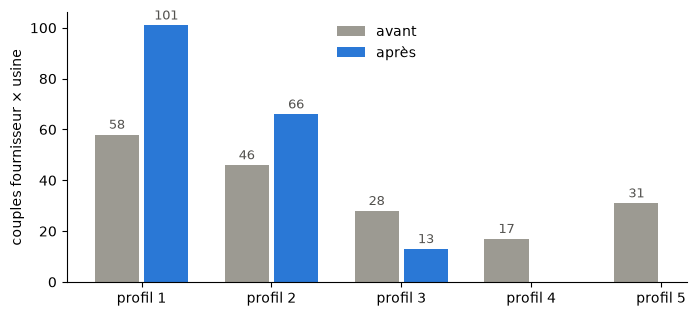

,1,2,3,4,5,total
avant,58.0,46.0,28.0,17.0,31.0,180.0
après,101.0,66.0,13.0,NaN,NaN,180.0


In [17]:
classes = range(1, 6)
counts = pd.DataFrame({"avant": profiles["current_profile"].value_counts(),
                       "après": profiles["profile"].value_counts()}).reindex(classes, fill_value=0)
fig, ax = plt.subplots(figsize=(8, 3.5))
x, width = np.arange(len(counts)), 0.38
for shift, column, color in ((-width / 2, "avant", "#9c9a92"), (width / 2, "après", "#2a78d6")):
    bars = ax.bar(x + shift, counts[column], width - 0.04, color=color, label=column)
    ax.bar_label(bars, fmt="%d", padding=2, fontsize=9, color="#52514e")
ax.set_xticks(x, [f"profil {k}" for k in counts.index])
ax.set_ylabel("couples fournisseur × usine")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()
counts.T.assign(total=lambda d: d.sum(axis=1))

## B3. Distribution du taux de remplissage

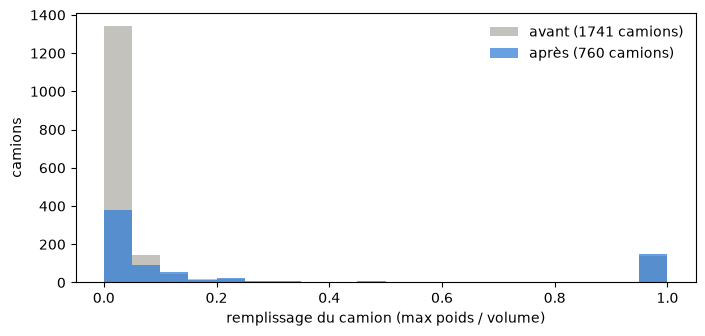

In [18]:
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(0, 1, 21)
ax.hist(before["fill"].clip(upper=1), bins=bins, alpha=0.6, label=f"avant ({len(before)} camions)", color="#9c9a92")
ax.hist(after["fill"].clip(upper=1), bins=bins, alpha=0.7, label=f"après ({len(after)} camions)", color="#2a78d6")
ax.set_xlabel("remplissage du camion (max poids / volume)")
ax.set_ylabel("camions")
ax.legend(frameon=False)
plt.show()
# TODO: même graphe par usine ; remplissage hors lignes imputées « camion plein »

## B4. Camions placés sur la grille tarifaire, avant / après

Chaque case de la grille est une tranche de distance × une tranche de poids. La couleur donne le **nombre de camions** qui
tombent dans cette case, avec la même échelle pour les deux graphes. Une consolidation réussie fait glisser les camions vers la
droite (tranches de poids élevées) : moins de camions, plus chargés.

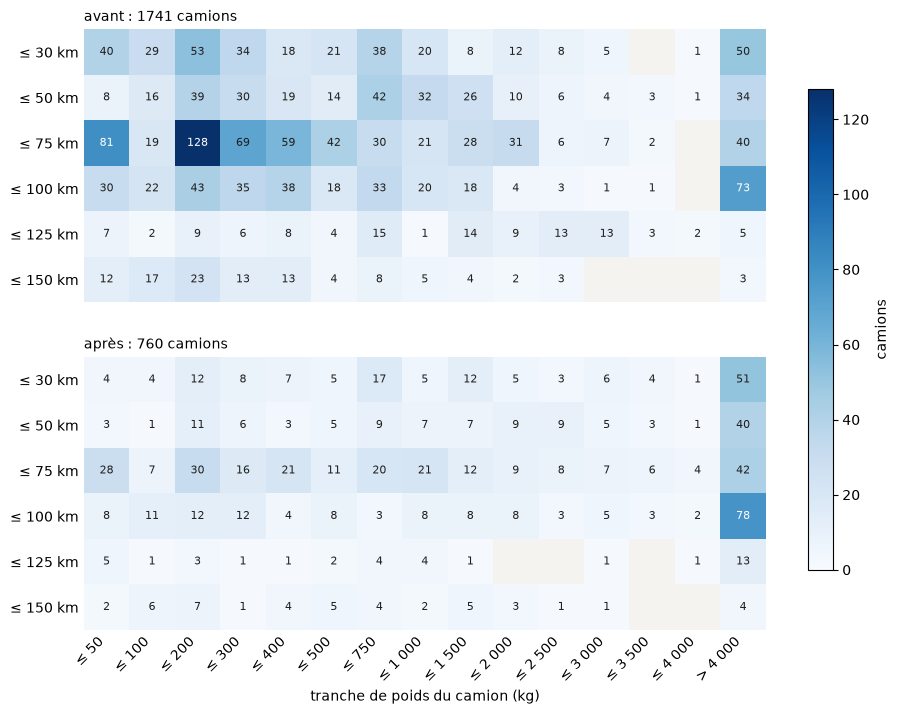

In [19]:
def grid_counts(frame: pd.DataFrame) -> pd.DataFrame:
    """Number of trucks per (distance bracket, weight bracket) of the rate sheet, read like the Tariff."""
    row = np.searchsorted(tariff.km, frame["distance"].to_numpy(float), side="left")
    col = np.searchsorted(tariff.kg, frame["weight"].to_numpy(float), side="left")
    table = pd.crosstab(row, col).reindex(index=range(len(tariff.km)), columns=range(len(tariff.kg)), fill_value=0)
    return table


bound = lambda v, unit: f"> {tariff.kg[-2]:,.0f}".replace(",", " ") if np.isinf(v) else f"≤ {v:,.0f}".replace(",", " ")
grids = {"avant": grid_counts(trucks_before), "après": grid_counts(trucks)}
used_rows = sorted(set().union(*(g.index[g.sum(axis=1) > 0] for g in grids.values())))
vmax = max(g.to_numpy().max() for g in grids.values())
cmap = plt.get_cmap("Blues").copy()
cmap.set_bad("#f4f3ef")

fig, axes = plt.subplots(2, 1, figsize=(11, 1.2 + 0.55 * len(used_rows) * 2), sharex=True)
for ax, (name, grid) in zip(axes, grids.items()):
    data = grid.loc[used_rows].to_numpy(float)
    image = ax.imshow(np.ma.masked_equal(data, 0), cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
    for (i, j), value in np.ndenumerate(data):
        if value:
            ax.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if value > vmax * 0.55 else "#1f1e1c")
    ax.set_yticks(range(len(used_rows)), [bound(tariff.km[r], "km") + " km" for r in used_rows])
    ax.set_title(f"{name} : {int(data.sum())} camions", loc="left", fontsize=10)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
axes[-1].set_xticks(range(len(tariff.kg)), [bound(v, "kg") for v in tariff.kg], rotation=45, ha="right")
axes[-1].set_xlabel("tranche de poids du camion (kg)")
fig.colorbar(image, ax=axes, shrink=0.8, label="camions")
plt.show()

## B5. Distribution des coûts

In [20]:
# TODO: coût par camion avant / après ; coût par couple avant / après (nuage cost_before vs cost_after) ; coût par usine et par semaine

## B6. Économies réalisées face au potentiel

- **Réalisé** : le saving du candidat (sortie 3).
- **Potentiel** : la borne inférieure du coût. Elle vient de `pl.lower_bound`, ou de l'optimum calculé par le solveur exact
  (109 412 €, dont 170 couples prouvés optimaux sur 180).

In [21]:
realised = saving["saving"].sum()
display(pd.DataFrame({"EUR": {"coût avant": saving["cost_before"].sum(), "coût après": saving["cost_after"].sum(),
                              "saving réalisé": realised}}).round(2))
# TODO: potentiel = coût avant − borne inférieure ; taux de réalisation = réalisé / potentiel
# TODO: classement des couples par saving (top 10) et couples sans gain

,EUR
coût avant,176724.61
coût après,110543.95
saving réalisé,66180.66


# Conclusion

TODO :
- les tests passés et les éventuelles limites ;
- le gain mesuré ;
- l'écart à l'optimum.